# Modelagem preditiva e avaliação de classificadores (SOMATIVA01.ipynb)

- **Repositório:** `machine-learning-portfolio`  
- **Tecnologias:** Scikit-Learn  
- **Arquivo Original:** `SOMATIVA01.ipynb`  

---


In [1]:
# incluir as funções e métodos necessários

from sklearn.neighbors import KNeighborsClassifier
from sklearn import model_selection
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn import tree
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import f1_score


In [2]:
import pandas as pd
import numpy as np


# loading attribute names
att=pd.read_csv('glass.csv', index_col=-1, nrows=0).columns.tolist()
print(att)


# loading the data
dataset = np.loadtxt('glass.csv', delimiter=",", skiprows=1)
X = dataset[:,0:9]
y = dataset[:,9]
print(X.shape)


['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe']
(214, 9)


KNN

Validação Cruzada - Acurácia Média: 96.28%
Acurácia: 96.26%
F1 Score: 96.35%


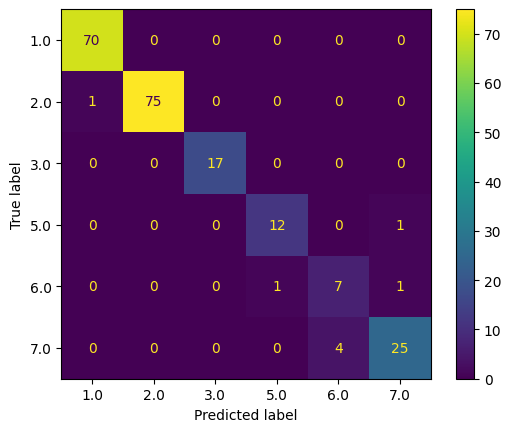

In [17]:
import pandas as pd
import numpy as np
from sklearn.model_selection import cross_val_predict, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

# Carregando os dados
dataset = np.loadtxt('glass.csv', delimiter=",", skiprows=1)
X = dataset[:, 1:10]  # Ignorando o primeiro atributo (ID)
y = dataset[:, 9]    # A classe está na coluna 9

# Inicializando o classificador KNN
knn = KNeighborsClassifier(
    n_neighbors=1,
    weights='uniform',
    algorithm='auto',
    leaf_size=30,
    metric='minkowski',
    p=2,
    metric_params=None,
    n_jobs=None
)

# Validação Cruzada com 5 folds
cv_scores = cross_val_score(knn, X, y, cv=5)
print(f'Validação Cruzada - Acurácia Média: {cv_scores.mean() * 100:.2f}%')

# Previsões de validação cruzada
y_pred_cv = cross_val_predict(knn, X, y, cv=5)

# Calculando a matriz de confusão
cm = confusion_matrix(y, y_pred_cv)

# Exibindo a matriz de confusão
unique_classes = np.unique(y)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=unique_classes)
disp.plot()

# Calculando o F1 Score e a acurácia
f1 = f1_score(y, y_pred_cv, average='weighted')
accuracy = accuracy_score(y, y_pred_cv)

# Resultados
print(f'Acurácia: {accuracy * 100:.2f}%')
print(f'F1 Score: {f1 * 100:.2f}%')


NAIVE BAYERS

Validação Cruzada - Acurácia Média: 97.67%
F1 Score: 97.69%
Accuracy: 97.66%


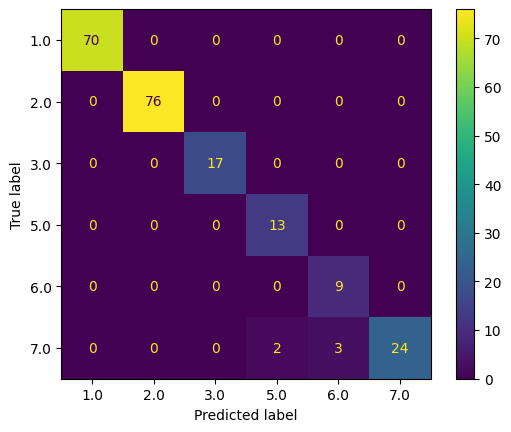

In [18]:
import pandas as pd
import numpy as np
from sklearn.model_selection import cross_val_predict, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

# Carregando os dados
dataset = np.loadtxt('glass.csv', delimiter=",", skiprows=1)
X = dataset[:, 1:10]  # Ignorando o primeiro atributo (ID)
y = dataset[:, 9]    # A classe está na coluna 9

# Inicializando o classificador Naive Bayes
gnb = GaussianNB()

# Validação Cruzada com 5 folds
cv_scores = cross_val_score(gnb, X, y, cv=5)
print(f'Validação Cruzada - Acurácia Média: {cv_scores.mean() * 100:.2f}%')

# Previsões de validação cruzada
y_pred_cv = cross_val_predict(gnb, X, y, cv=5)

# Calculando a matriz de confusão
cm = confusion_matrix(y, y_pred_cv)

# Exibindo a matriz de confusão
unique_classes = np.unique(y)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=unique_classes)
disp.plot()

# Calculando as métricas de desempenho
precision = precision_score(y, y_pred_cv, average='weighted')
recall = recall_score(y, y_pred_cv, average='weighted')
f1 = f1_score(y, y_pred_cv, average='weighted')
accuracy = accuracy_score(y, y_pred_cv)

# Resultados
print(f'F1 Score: {f1 * 100:.2f}%')
print(f'Accuracy: {accuracy * 100:.2f}%')


ARVORE DE DECISÃO

Nome do atributo mais importante: Fe
Validação Cruzada - Acurácia Média: 100.00%
Acurácia: 99.07%
F1 Score: 96.94%


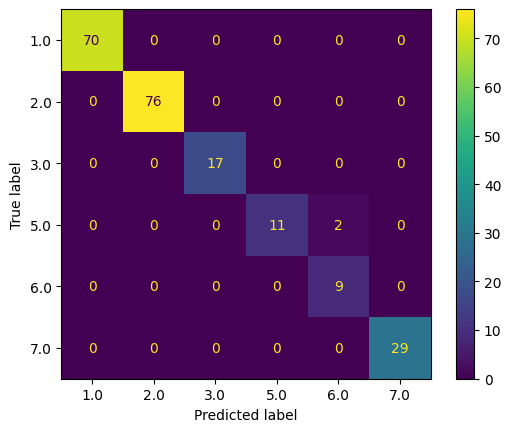

In [29]:
import pandas as pd
import numpy as np
from sklearn.model_selection import cross_val_predict, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

# Carregando os dados
dataset = np.loadtxt('glass.csv', delimiter=",", skiprows=1)
X = dataset[:, 1:10]  # Ignorando o primeiro atributo (ID)
y = dataset[:, 9]    # A classe está na coluna 9

# Nomes dos atributos (exemplo)
attribute_names = ['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe']

# Inicializando o classificador de Árvore de Decisão
dt = DecisionTreeClassifier(
    criterion='gini',  # ou 'entropy'
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=None,
    random_state=None
)

# Ajustando o modelo com todos os dados
dt.fit(X, y)

# Determinando a importância dos atributos
importances = dt.feature_importances_
indices = np.argsort(importances)[::-1]

# Exibindo o nome do atributo mais importante
most_important_attribute = attribute_names[indices[0]]
print(f'Nome do atributo mais importante: {most_important_attribute}')

# Validação Cruzada com 5 folds
cv_scores = cross_val_score(dt, X, y, cv=5)
print(f'Validação Cruzada - Acurácia Média: {cv_scores.mean() * 100:.2f}%')

# Previsões de validação cruzada
y_pred_cv = cross_val_predict(dt, X, y, cv=5)

# Calculando a matriz de confusão
cm = confusion_matrix(y, y_pred_cv)

# Exibindo a matriz de confusão
unique_classes = np.unique(y)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=unique_classes)
disp.plot()

# Calculando o F1 Score e a acurácia
f1 = f1_score(y, y_pred_cv, average='macro')
accuracy = accuracy_score(y, y_pred_cv)

# Resultados
print(f'Acurácia: {accuracy * 100:.2f}%')
print(f'F1 Score: {f1 * 100:.2f}%')


SVM

Validação Cruzada - Acurácia Média: 98.60%
Acurácia: 98.60%
F1 Score: 98.63%


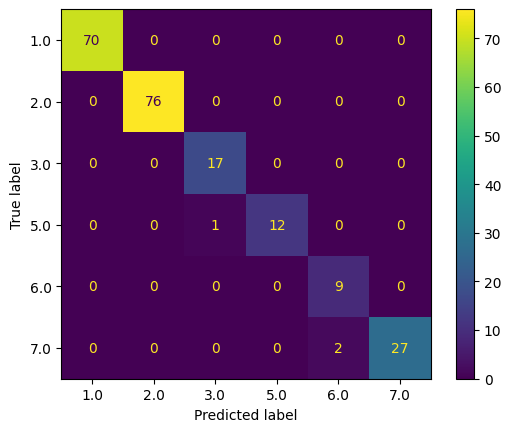

In [20]:
import pandas as pd
import numpy as np
from sklearn.model_selection import cross_val_predict, cross_val_score
from sklearn.svm import SVC
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

# Carregando os dados
dataset = np.loadtxt('glass.csv', delimiter=",", skiprows=1)
X = dataset[:, 1:10]  # Ignorando o primeiro atributo (ID)
y = dataset[:, 9]    # A classe está na coluna 9

# Inicializando o classificador SVM
svm = SVC(
    C=1.0,
    kernel='poly',
    gamma='auto',
)

# Validação Cruzada com 5 folds
cv_scores = cross_val_score(svm, X, y, cv=5, scoring='accuracy')
print(f'Validação Cruzada - Acurácia Média: {cv_scores.mean() * 100:.2f}%')

# Previsões de validação cruzada
y_pred_cv = cross_val_predict(svm, X, y, cv=5)

# Calculando a matriz de confusão
cm = confusion_matrix(y, y_pred_cv)

# Exibindo a matriz de confusão
unique_classes = np.unique(y)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=unique_classes)
disp.plot()

# Calculando o F1 Score e a acurácia
f1 = f1_score(y, y_pred_cv, average='weighted')
accuracy = accuracy_score(y, y_pred_cv)

# Resultados
print(f'Acurácia: {accuracy * 100:.2f}%')
print(f'F1 Score: {f1 * 100:.2f}%')


MLP

/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perce

Validação Cruzada - F1 Score Médio: 96.33%


/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perce

Acurácia: 95.79%
F1 Score: 95.93%


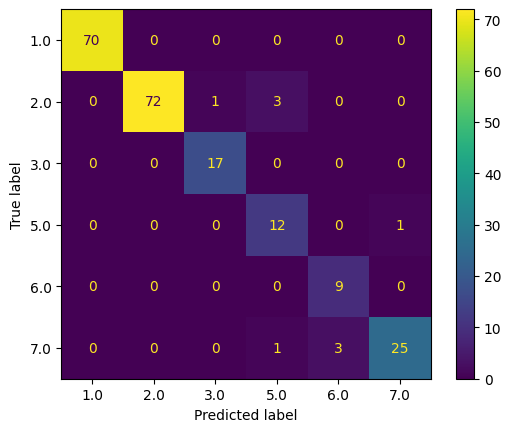

In [23]:
import pandas as pd
import numpy as np
from sklearn.model_selection import cross_val_predict, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

# Carregando os dados
dataset = np.loadtxt('glass.csv', delimiter=",", skiprows=1)
X = dataset[:, 1:10]  # Ignorando o primeiro atributo (ID)
y = dataset[:, 9]    # A classe está na coluna 9

# Inicializando o classificador MLP com parâmetros específicos
mlp = MLPClassifier(
    hidden_layer_sizes=(100,),
    activation='relu',
    solver='adam',
    alpha=0.0001,
    batch_size='auto',
    learning_rate='constant',
    learning_rate_init=0.001,
    max_iter=1000,
    random_state=42
)

# Validação Cruzada com 5 folds e cálculo do F1 Score
cv_scores = cross_val_score(mlp, X, y, cv=5, scoring='f1_weighted')
print(f'Validação Cruzada - F1 Score Médio: {cv_scores.mean() * 100:.2f}%')

# Previsões de validação cruzada
y_pred_cv = cross_val_predict(mlp, X, y, cv=5)

# Calculando a matriz de confusão
cm = confusion_matrix(y, y_pred_cv)

# Exibindo a matriz de confusão
unique_classes = np.unique(y)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=unique_classes)
disp.plot()

# Calculando o F1 Score e a acurácia
f1 = f1_score(y, y_pred_cv, average='weighted')
accuracy = accuracy_score(y, y_pred_cv)

# Resultados
print(f'Acurácia: {accuracy * 100:.2f}%')
print(f'F1 Score: {f1 * 100:.2f}%')


LDA

Validação Cruzada - Acurácia Média: 61.68%
Acurácia: 61.68%
F1 Score: 59.35%


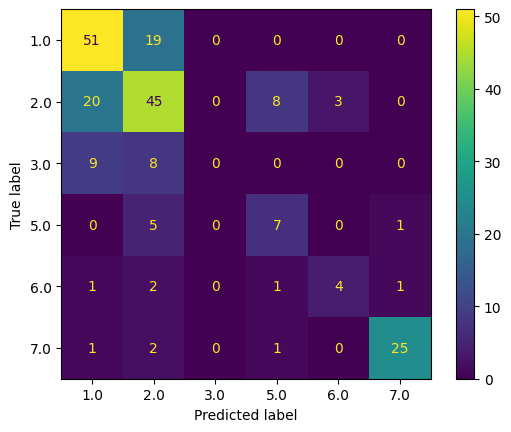

In [22]:
import pandas as pd
import numpy as np
from sklearn.model_selection import cross_val_predict, cross_val_score
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

# Carregando os dados
dataset = np.loadtxt('glass.csv', delimiter=",", skiprows=1)
X = dataset[:, 1:10]  # Ignorando o primeiro atributo (ID)
y = dataset[:, 9]    # A classe está na coluna 9

# Inicializando o classificador LDA com parâmetros específicos
lda = LinearDiscriminantAnalysis(
    solver='svd',
    shrinkage=None,
    priors=None,
    n_components=None,
    store_covariance=False,
    tol=0.0001
)

# Validação Cruzada com 5 folds
cv_scores = cross_val_score(lda, X, y, cv=5, scoring='accuracy')
print(f'Validação Cruzada - Acurácia Média: {cv_scores.mean() * 100:.2f}%')

# Previsões de validação cruzada
y_pred_cv = cross_val_predict(lda, X, y, cv=5)

# Calculando a matriz de confusão
cm = confusion_matrix(y, y_pred_cv)

# Exibindo a matriz de confusão
unique_classes = np.unique(y)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=unique_classes)
disp.plot()

# Calculando o F1 Score e a acurácia
f1 = f1_score(y, y_pred_cv, average='weighted')
accuracy = accuracy_score(y, y_pred_cv)

# Resultados
print(f'Acurácia: {accuracy * 100:.2f}%')
print(f'F1 Score: {f1 * 100:.2f}%')


Classe 0: 0 amostras
Classe 1: 70 amostras
Classe 2: 76 amostras
Classe 3: 17 amostras
Classe 4: 0 amostras
Classe 5: 13 amostras
Classe 6: 9 amostras
Classe 7: 29 amostras


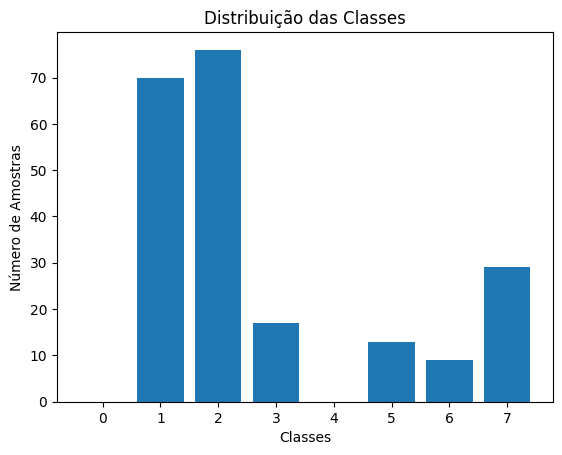

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Carregando os dados
dataset = np.loadtxt('glass.csv', delimiter=",", skiprows=1)
y = dataset[:, 9]  # A classe está na coluna 9

# Contando a frequência de cada classe
class_counts = np.bincount(y.astype(int))

# Exibindo a distribuição das classes
for i, count in enumerate(class_counts):
    print(f'Classe {i}: {count} amostras')

# Plotando a distribuição das classes
plt.bar(range(len(class_counts)), class_counts, tick_label=range(len(class_counts)))
plt.xlabel('Classes')
plt.ylabel('Número de Amostras')
plt.title('Distribuição das Classes')
plt.show()
